In [4]:
from src.utils.data_utils import load_final_df
from src.analysis.virality_analysis.get_viral_posts import get_viral_posts, plot_viral_posts
import numpy as np
import pandas as pd

df = load_final_df(calculate_rss=False, drop_nan_upvotes=False)
nan_df = df[df["ups"].isna()]
non_nan_df = df[~df["ups"].isna()]

mask = non_nan_df['upvote_ratio'] > 0
total_votes = pd.Series(0.0, index=non_nan_df.index) # assumption: if ups = 0 or upvote_ratio = 0 we assume downs = 0
downs = pd.Series(0.0, index=non_nan_df.index)

total_votes.loc[mask] = non_nan_df.loc[mask, 'ups'] / non_nan_df.loc[mask, 'upvote_ratio']
downs.loc[mask] = total_votes.loc[mask] - non_nan_df.loc[mask, 'ups']

subreddit_subscribers = np.maximum(non_nan_df["subreddit_subscribers"], 0)

non_nan_df = non_nan_df.assign(
    total_votes=total_votes,
    downs=downs,
    subreddit_subscribers=subreddit_subscribers,
    virality_rss=((2*non_nan_df["ups"] + non_nan_df["downs"]) / np.sqrt(subreddit_subscribers + 1))
)

non_nan_df = get_viral_posts(non_nan_df, virality_percentile=0.98, window_size='60D')

pd.set_option('display.max_columns', None)
non_nan_df.head(5)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,source_type,Num_characters,Num_characters_no_space,Frac_alpha,Frac_digits,Frac_uppercase,Frac_whitespace,Frac_special,Num_words,Num_unique_words,Num_long_words,Avg_word_length,Num_unique_stopwords,Frac_stopwords,Num_sentences,Num_long_sentences,Avg_chars_per_sentence,Avg_words_per_sentence,Automated_readability_index,Sentiment_pos_vader,Sentiment_neg_vader,Sentiment_compound_vader,LIWC_Funct,LIWC_Pronoun,LIWC_Ppron,LIWC_I,LIWC_We,LIWC_You,LIWC_SheHe,LIWC_They,LIWC_Ipron,LIWC_Article,LIWC_Verbs,LIWC_AuxVb,LIWC_Past,LIWC_Present,LIWC_Future,LIWC_Adverbs,LIWC_Prep,LIWC_Conj,LIWC_Negate,LIWC_Quant,LIWC_Numbers,LIWC_Swear,LIWC_Social,LIWC_Family,LIWC_Friends,LIWC_Humans,LIWC_Affect,LIWC_Posemo,LIWC_Negemo,LIWC_Anx,LIWC_Anger,LIWC_Sad,LIWC_CogMech,LIWC_Insight,LIWC_Cause,LIWC_Discrep,LIWC_Tentat,LIWC_Certain,LIWC_Inhib,LIWC_Incl,LIWC_Excl,LIWC_Percept,LIWC_See,LIWC_Hear,LIWC_Feel,LIWC_Bio,LIWC_Body,LIWC_Health,LIWC_Sexual,LIWC_Ingest,LIWC_Relativ,LIWC_Motion,LIWC_Space,LIWC_Time,LIWC_Work,LIWC_Achiev,LIWC_Leisure,LIWC_Home,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler,source_cluster_level_0,target_cluster_level_0,source_cluster_level_1,target_cluster_level_1,source_cluster_level_2,target_cluster_level_2,source_cluster_level_3,target_cluster_level_3,source_cluster_level_4,target_cluster_level_4,approved_at_utc,subreddit,user_reports,saved,mod_reason_title,gilded,clicked,link_flair_richtext,subreddit_name_prefixed,hidden,pwls,link_flair_css_class,downs,top_awarded_type,hide_score,name,quarantine,link_flair_text_color,upvote_ratio,author_flair_background_color,subreddit_type,ups,total_awards_received,author_flair_template_id,is_original_content,is_reddit_media_domain,is_meta,category,link_flair_text,can_mod_post,score,approved_by,is_created_from_ads_ui,edited,author_flair_css_class,gildings,content_categories,is_self,mod_note,created,link_flair_type,wls,removed_by_category,banned_by,domain,allow_live_comments,likes,suggested_sort,banned_at_utc,view_count,archived,no_follow,is_crosspostable,pinned,over_18,all_awardings,awarders,media_only,can_gild,spoiler,locked,author_flair_text,treatment_tags,visited,removed_by,num_reports,distinguished,subreddit_id,author_is_blocked,mod_reason_by,removal_reason,id,is_robot_indexable,num_duplicates,report_reasons,author,discussion_type,num_comments,send_replies,contest_mode,author_flair_text_color,permalink,stickied,url,subreddit_subscribers,created_utc,num_crossposts,mod_reports,is_video,title,selftext,source_supercluster,target_supercluster,total_votes,virality_rss,moving_avg_virality,moving_std_virality,z_score,is_viral
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,body,101.0,98.0,0.742574,0.019802,0.049505,0.059406,0.178218,14.0,14.0,2.0,5.714286,1.0,0.071429,2.0,0.0,49.500000,7.000000,16.049286,0.472,0.000,0.5538,0.066667,0.066667,0.066667,0.066667,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.066667,0.000000,0.000000,0.066667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.133333,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.066667,0.000000,0.000000,0.066667,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.066667,0.066667,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.066667,0.000000,0.066667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,ALL,ALL,Political Philosophy Debates,Global Sports MMA,UK Japan Circlejerk,European Soccer Clubs,theredlion,soccer,theredlion,soccer,NaN,TheRedLion,[],False,NaN,0.0,False,[],r/TheRedLion,False,6.0,NaN,1.849315,NaN,False,t3_1u4qkd,False,dark,0.73,NaN,public,5.0,0.0,NaN,False,False,False,NaN,NaN,False,5.0,NaN,False,FALSE,NaN,{},NaN,True,NaN,NaN,text,6.0,NaN,NaN,self.TheRedLion,False,NaN,NaN,NaN,NaN,False,False,True,False,False,[],[],False,False,False,False,Petes not so secret gay lover,NaN,False,NaN,NaN,NaN,t5_2vrbs,False,NaN,NaN,1u4qkd,True,NaN,NaN,HarryBlessKnapp

In [ ]:
non_nan_df = non_nan_df.iloc[:, list(range(92)) + [-1, -7, -8]]
non_nan_df = non_nan_df.drop(columns=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP"])

non_nan_df = pd.get_dummies(non_nan_df, columns=["source_supercluster", "target_supercluster", "source_type"], drop_first=True)


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ----- 1. Choose your columns -----
X = non_nan_df.drop(columns=["is_viral"])   # predictors
y = non_nan_df["is_viral"]                  # label column

# ----- 2. Train/test split -----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ----- 3. Fit Random Forest -----
rf = RandomForestClassifier(
    n_estimators=300,      # number of trees
    max_depth=10,        # let trees grow fully
    min_samples_split=2,
    random_state=42,
    n_jobs=-1,
    class_weight={0: 1, 1: 25},
)

rf.fit(X_train, y_train)

# ----- 4. Evaluate -----
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)


Accuracy: 0.9657027572293208


In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[True, False])
cm_df = pd.DataFrame(cm, index=["Actual True", "Actual False"], columns=["Pred True", "Pred False"])
cm_df

,Pred True,Pred False
Actual True,508,2374
Actual False,2471,135912


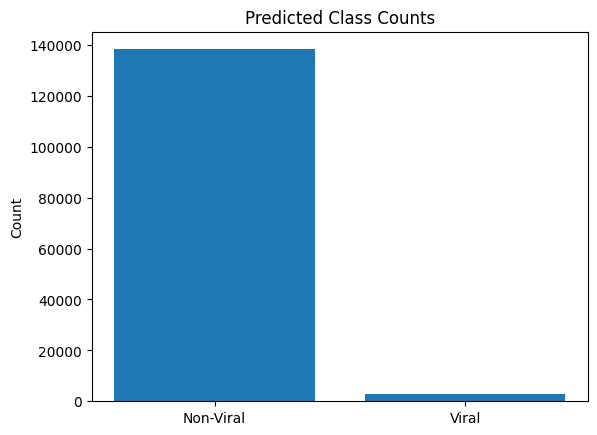

Percentage of predictions that are 1: 2.1088026050330937


In [29]:
import numpy as np
import matplotlib.pyplot as plt

pred_counts = np.bincount(y_pred)

plt.bar([0,1], pred_counts)
plt.xticks([0,1], ["Non-Viral", "Viral"])
plt.title("Predicted Class Counts")
plt.ylabel("Count")
plt.savefig("predicted_class_counts.svg", format="svg")
plt.show()

print("Percentage of predictions that are 1:", pred_counts[1] / len(y_pred) * 100)


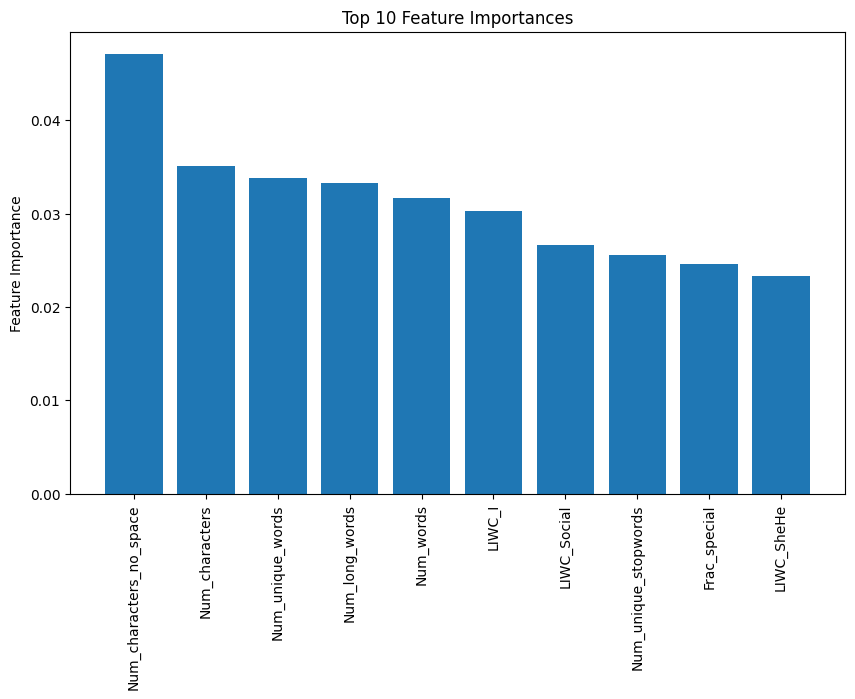

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Extract importances and feature names
importances = rf.feature_importances_
feature_names = X_train.columns

# Sort and select top 10
idx = np.argsort(importances)[-10:]
top_features = feature_names[idx]
top_importances = importances[idx]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(top_features[::-1], top_importances[::-1])
plt.ylabel("Feature Importance")
plt.xticks(rotation=90)
plt.title("Top 10 Feature Importances")
plt.savefig("top_10_feature_importances.svg", format="svg", bbox_inches='tight')
